# SuperStore Data Analytics Project: From Raw Data to Interactive Dashboard

### Objective
- Work with a real-world dataset,
- Clean and prepare it (data wrangling),
- Perform exploratory data analysis (EDA),
- Build an interactive dashboard using Python.


### Step 1. Data Wrangling: Load your dataset using Python (Pandas) and clean it.

In [ ]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load superstore data to pandas dataframe
encodings = ["utf-8", "utf-8-sig", "iso-8859-1", "latin1", "cp1252", "mixed","windows-1252" ]
for encoding in encodings:
  try:
    df = pd.read_csv('Superstore.csv', encoding=encoding)
    break
  except Exception:
    pass
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


#### 1.2. Basic insight from Superstore Dataset

In [ ]:
# Data structure: Concise summary of the dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [ ]:
# Identify missing values
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [ ]:
# Clean Data & Fix Data Types
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df['Sales'] = pd.to_numeric(df['Sales']).fillna(0)
df['Profit'] = pd.to_numeric(df['Profit']).fillna(0)

df[['Order Date', 'Ship Date', 'Sales', 'Profit']].dtypes

,0
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Sales,float64
Profit,float64


In [ ]:
# Remove Duplicates, order id has 8 duplicates, show how many duplicates removed, some product id contains more than two names
df = df.drop_duplicates()

#investigate data
print('the number of product name', len(df['Product Name'].unique()))
print('the number of product ID',len(df['Product ID'].unique()))

# Check product IDs with more than one product name
Test=df.groupby('Product ID')['Product Name'].nunique().sort_values(ascending=False)
print(len(Test[Test==2]))
print(len(Test[Test==1]))
print(len(Test[Test==0]))
print(df['Order ID'].duplicated().sum())

Test1=df.groupby('Order ID')['Product ID'].nunique().sort_values(ascending=False)
print(Test1.max())

the number of product name 1850
the number of product ID 1862
32
1830
0
4985
14


In [ ]:
#investigate Order duplicates
j=0
for i in range(0, Test1.max() + 1):
  print(f'the number of order id that has  {i} Product ID ',len(Test1[Test1==i]))
  j += i * len(Test1[Test1 == i])
print('numbre of order id including duplicate with different product Id ',j)


the number of order id that has  0 Product ID  0
the number of order id that has  1 Product ID  2540
the number of order id that has  2 Product ID  1218
the number of order id that has  3 Product ID  607
the number of order id that has  4 Product ID  333
the number of order id that has  5 Product ID  157
the number of order id that has  6 Product ID  70
the number of order id that has  7 Product ID  52
the number of order id that has  8 Product ID  15
the number of order id that has  9 Product ID  10
the number of order id that has  10 Product ID  3
the number of order id that has  11 Product ID  2
the number of order id that has  12 Product ID  1
the number of order id that has  13 Product ID  0
the number of order id that has  14 Product ID  1
numbre of order id including duplicate with different product Id  9986


In [ ]:
# Filter and display all duplicate entries based on Order ID and Product ID
duplicates = df[df.duplicated(subset=['Order ID', 'Product ID'], keep=False)]

# Sort them so matching duplicates are right next to each other
duplicates_sorted = duplicates.sort_values(by=['Order ID', 'Product ID'])

# View key columns of the duplicate rows
duplicates_sorted[['Order ID','Ship Date','Ship Mode','Product ID', 'Product Name', 'Segment', 'City','State', 'Postal Code','Region','Category','Sub-Category']]

,Order ID,Ship Date,Ship Mode,Product ID,Product Name,Segment,City,State,Postal Code,Region,Category,Sub-Category
6498,CA-2015-103135,2015-07-28,Standard Class,OFF-BI-10000069,"GBC Prepunched Paper, 19-Hole, for Binding Sys...",Home Office,Louisville,Kentucky,40214,South,Office Supplies,Binders
6500,CA-2015-103135,2015-07-28,Standard Class,OFF-BI-10000069,"GBC Prepunched Paper, 19-Hole, for Binding Sys...",Home Office,Louisville,Kentucky,40214,South,Office Supplies,Binders
350,CA-2016-129714,2016-09-03,First Class,OFF-PA-10001970,Xerox 1881,Home Office,New York City,New York,10009,East,Office Supplies,Paper
352,CA-2016-129714,2016-09-03,First Class,OFF-PA-10001970,Xerox 1881,Home Office,New York City,New York,10009,East,Office Supplies,Paper
1300,CA-2016-137043,2016-12-25,Second Class,FUR-FU-10003664,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",Consumer,Springfield,Virginia,22153,South,Furniture,Furnishings
1301,CA-2016-137043,2016-12-25,Second Class,FUR-FU-10003664,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",Consumer,Springfield,Virginia,22153,South,Furniture,Furnishings
9168,CA-2016-140571,2016-03-19,Standard Class,OFF-PA-10001954,Xerox 1964,Home Office,Jackson,Mississippi,39212,South,Office Supplies,Paper
9169,CA-2016-140571,2016-03-19,Standard Class,OFF-PA-10001954,Xerox 1964,Home Office,Jackson,Mississippi,39212,South,Office Supplies,Paper
7881,CA-2017-118017,2017-12-06,Second Class,TEC-AC-10002006,Memorex Micro Travel Drive 16 GB,Consumer,Thornton,Colorado,80229,West,Technology,Accessories
7882,CA-2017-118017,2017-12-06,Second Class,TEC-AC-10002006,Memorex Micro Travel Drive 16 GB,Consumer,Thornton,Colorado,80229,West,Technology,Accessories


In [ ]:
len(duplicates_sorted)

16

In [ ]:
# 1. Identify columns to update
target_cols = ['Sales', 'Quantity', 'Profit']

# 2. Calculate group means for duplicate Order ID + Product ID pairs and assign directly
df.loc[duplicates_sorted.index, target_cols] = df.groupby(['Order ID', 'Product ID'])[target_cols].transform('mean')

# 3. Now drop the duplicate rows, keeping the first occurrence (which now holds the mean values)
df_cleaned = df.drop_duplicates(subset=['Order ID', 'Product ID','Product Name'], keep='first')


df_cleaned.shape

/tmp/ipykernel_1842/3843984313.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[7.5 7.5 3.  3.  4.5 4.5 8.  8.  7.  7.  6.  6.  2.  2.  6.  6. ]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[duplicates_sorted.index, target_cols] = df.groupby(['Order ID', 'Product ID'])[target_cols].transform('mean')


(9986, 21)

In [ ]:
#display all product ID that have 2 products name  along with product name
Test=df_cleaned.groupby('Product ID')['Product Name'].nunique().sort_values(ascending=False)
pro_ids=Test[Test==2].index
df_cleaned[df_cleaned['Product ID'].isin(pro_ids)][['Product ID', 'Product Name']].drop_duplicates().sort_values('Product ID')

,Product ID,Product Name
2471,FUR-BO-10002213,"Sauder Forest Hills Library, Woodland Oak Finish"
2115,FUR-BO-10002213,DMI Eclipse Executive Suite Bookcases
66,FUR-CH-10001146,"Global Value Mid-Back Manager's Chair, Gray"
128,FUR-CH-10001146,"Global Task Chair, Black"
1459,FUR-FU-10001473,DAX Wood Document Frame
...,...,...
1219,TEC-PH-10002200,Samsung Galaxy Note 2
2596,TEC-PH-10002310,Plantronics Calisto P620-M USB Wireless Speake...
1378,TEC-PH-10002310,Panasonic KX T7731-B Digital phone
922,TEC-PH-10004531,OtterBox Commuter Series Case - iPhone 5 & 5s


In [ ]:
# Calculate the most frequent name ONLY for the 32 affected Product IDs
most_frequent_names = (df_cleaned[df_cleaned['Product ID'].isin(pro_ids)].groupby('Product ID')['Product Name'].agg(lambda x: x.mode()[0]).to_dict())
# Convert dictionary items to a clean 2-column DataFrame
d = pd.DataFrame(list(most_frequent_names.items()), columns=['Product ID', 'Product Name'])
d.duplicated().value_counts()

,count
False,32


In [ ]:
# Apply the mapping ONLY to the rows matching those 32 Product IDs
df_cleaned.loc[df_cleaned['Product ID'].isin(pro_ids), 'Product Name'] = (df_cleaned['Product ID'].map(most_frequent_names))

In [ ]:
Test3=df_cleaned.groupby('Product ID')['Product Name'].nunique().sort_values(ascending=False)
Test3.max()
# should be 1

1

In [ ]:
# Feature Engineering
df_cleaned['Year'] = df_cleaned['Order Date'].dt.year
df_cleaned['Month'] = df_cleaned['Order Date'].dt.month
df_cleaned['Day'] = df_cleaned['Order Date'].dt.day
df_cleaned['Profit_Margin'] = np.where(df_cleaned['Sales'] != 0, df_cleaned['Profit'] / df_cleaned['Sales'], 0)
df_cleaned["Shipping Days"] = (df_cleaned["Ship Date"] - df_cleaned["Order Date"]).dt.days
df_cleaned.head()

/tmp/ipykernel_1842/3278137037.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cleaned['Year'] = df_cleaned['Order Date'].dt.year
/tmp/ipykernel_1842/3278137037.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cleaned['Month'] = df_cleaned['Order Date'].dt.month
/tmp/ipykernel_1842/3278137037.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pand

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Day,Profit_Margin,Shipping Days
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2016,11,8,0.1600,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2016,11,8,0.3000,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2016,6,12,0.4700,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2015,10,11,-0.4000,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2015,10,11,0.1125,7


### **Step 2 : Exploratory Data Analysis (EDA): Explore the dataset and answer business questions.**



#### 1. Basic Stats

In [ ]:

print("--- BASIC STATISTICS ---")
print(df_cleaned[['Sales', 'Profit', 'Profit_Margin']].describe())
print("\n")

--- BASIC STATISTICS ---
              Sales       Profit  Profit_Margin
count   9986.000000  9986.000000    9986.000000
mean     229.784611    28.613820       0.120185
std      623.370428   234.319651       0.466894
min        0.444000 -6599.978000      -2.750000
25%       17.248000     1.728000       0.075000
50%       54.384000     8.641350       0.270000
75%      209.880000    29.353800       0.362500
max    22638.480000  8399.976000       0.500000




#### 2. Group Analysis

In [ ]:
# Sales by Category
sales_by_category = df_cleaned.groupby('Category')['Sales'].sum().round(2).reset_index()
print("--- SALES BY CATEGORY ---")
print(sales_by_category)
print("\n")

# Profit by Region
profit_by_region = df_cleaned.groupby('Region')['Profit'].sum().round(2).reset_index()
print("--- PROFIT BY REGION ---")
print(profit_by_region)
print("\n")

# Monthly Trend of Sales
monthly_trends = df_cleaned.groupby('Month')['Sales'].sum().round(2).reset_index()
month = ['January','February','March','April','May','June','July','August','September','October','November','December']
monthly_trends['Month'] = month
print("--- MONTHLY SALES TRENDS ---")
print(monthly_trends)
print("\n")

--- SALES BY CATEGORY ---
          Category      Sales
0        Furniture  741288.85
1  Office Supplies  717626.14
2       Technology  835714.14


--- PROFIT BY REGION ---
    Region     Profit
0  Central   39706.36
1     East   91201.78
2    South   46423.33
3     West  108406.14


--- MONTHLY SALES TRENDS ---
        Month      Sales
0     January   94924.84
1    February   59751.25
2       March  204822.77
3       April  137130.40
4         May  155028.81
5        June  152718.68
6        July  147125.52
7      August  159044.06
8   September  307613.11
9     October  200322.98
10   November  351372.31
11   December  324774.39




In [ ]:
# Calculate total profit for each product by category
product_profit = df_cleaned.groupby(['Category', 'Product Name'])['Profit'].sum().reset_index()

# 1. Top 5 Products with Most Profit per Category
top_profitable = product_profit.sort_values(['Category', 'Profit'], ascending=[True, False]).groupby('Category').head(5).round()
print("\n--- Top 5 Most Profitable Products per Category ---")
display(top_profitable)


--- Top 5 Most Profitable Products per Category ---


,Category,Product Name,Profit
218,Furniture,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",1927.0
169,Furniture,Global Deluxe High-Back Manager's Chair,1559.0
231,Furniture,Hon Pagoda Stacking Chairs,1541.0
210,Furniture,Hon 4070 Series Pagoda Armless Upholstered Sta...,1389.0
306,Furniture,Office Star - Professional Matrix Back Chair w...,1306.0
764,Office Supplies,Fellowes PB500 Electric Punch Plastic Comb Bin...,7753.0
878,Office Supplies,Ibico EPK-21 Electric Binding System,3345.0
857,Office Supplies,Honeywell Enviracaire Portable HEPA Air Cleane...,3247.0
763,Office Supplies,Fellowes PB300 Plastic Comb Binding Machine,2518.0
880,Office Supplies,Ibico Ibimaster 300 Manual Binding System,2318.0


In [ ]:
# 2. Top 5 Products with Most Loss per Category
top_loss = product_profit.sort_values(['Category', 'Profit'], ascending=[True, True]).groupby('Category').head(5).round()
print("\n--- Top 5 Most Loss-Making Products per Category ---")
display(top_loss)


--- Top 5 Most Loss-Making Products per Category ---


,Category,Product Name,Profit
63,Furniture,Chromcraft Bull-Nose Wood Oval Conference Tabl...,-2876.0
42,Furniture,Bush Advantage Collection Racetrack Conference...,-1934.0
21,Furniture,Balt Solid Wood Round Tables,-1201.0
37,Furniture,BoxOffice By Design Rectangular and Half-Moon ...,-1148.0
312,Furniture,"Riverside Furniture Oval Coffee Table, Oval En...",-1147.0
788,Office Supplies,GBC DocuBind P400 Electric Binding System,-1878.0
920,Office Supplies,Martin Yale Chadless Opener Electric Letter Op...,-1299.0
387,Office Supplies,3.6 Cubic Foot Counter Height Office Refrigerator,-872.0
1172,Office Supplies,Tennsco Single-Tier Lockers,-826.0
1072,Office Supplies,"SAFCO Commercial Wire Shelving, Black",-635.0


#### 3. Data Visualizations:

# **Question 1**: What are the total Product Sales by Category?

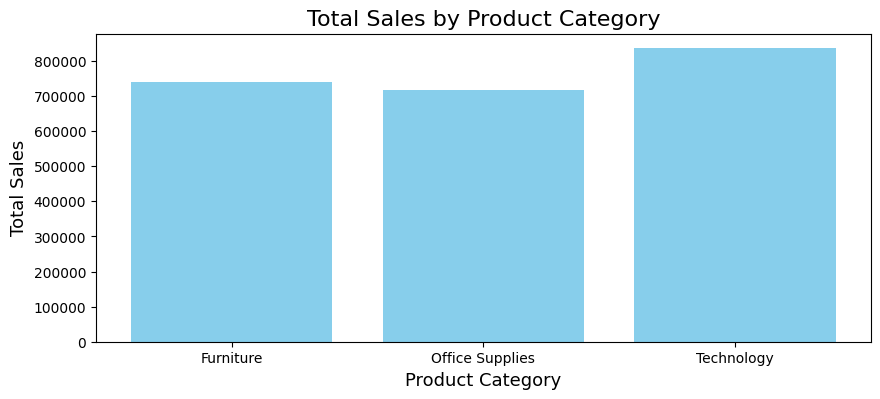

In [ ]:
# Plot 1: Bar chart -> Sales by Product Category
fig, axes = plt.subplots(figsize=(10, 4))

if 'Category' in df_cleaned.columns:
    axes.bar(sales_by_category['Category'], sales_by_category['Sales'], color='skyblue')
    axes.set_title('Total Sales by Product Category', fontsize=16)
    axes.set_xlabel('Product Category', fontsize=13)
    axes.set_ylabel('Total Sales', fontsize=13)

    plt.show()

**Key Insight:** Technology generates the highest revenue, totaling **&#36;836,154.03**. Furniture follows with **&#36;741,999.80**, and Office Supplies rounds out the categories with **&#36;$719,047.03**.

# **Question 2**: What is the trend of monthly sales YoY?

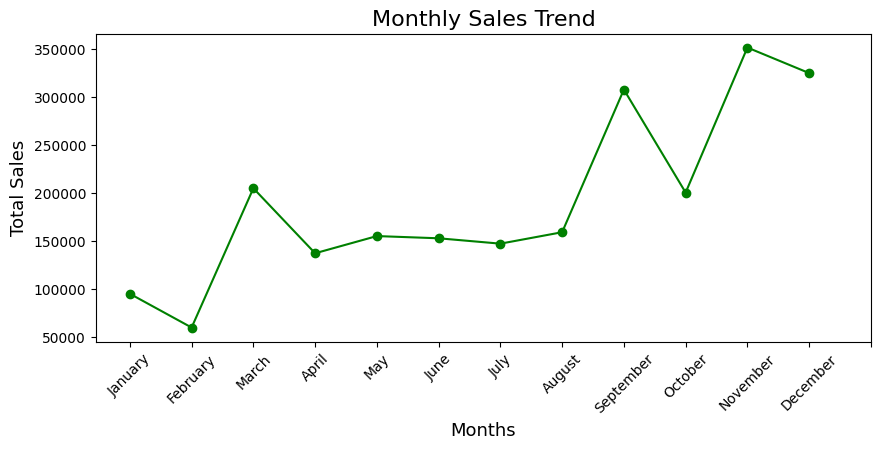

In [ ]:
# Plot 2: Line chart -> Trend over time (Monthly Sales)
fig, axes = plt.subplots(figsize=(10, 4))

if 'Month' in df.columns:
    axes.plot(monthly_trends['Month'], monthly_trends['Sales'], marker='o', linestyle='-', color='green')
    axes.set_title('Monthly Sales Trend', fontsize=16)
    axes.set_xlabel('Months', fontsize=13)
    axes.set_ylabel('Total Sales', fontsize=13)
    axes.set_xticks(range(0, 13))
    axes.tick_params(axis='x', rotation=45)

**Key Insight:** The late fall and holiday shopping season is the undeniable peak performance period. November is the highest-grossing month at **&#36;352,461.07**, followed closely by December (**&#36;325,293.50**) and September (**&#36;307,649.95**).

# **Question 3**: What is the Sales distribution accross regions?

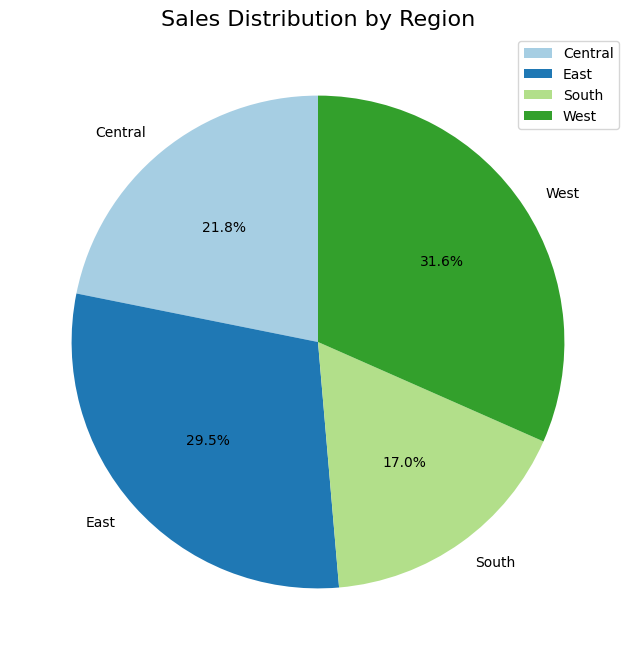

In [ ]:
# Plot 3: Pie chart -> Distribution (Sales by Region)
fig, axes = plt.subplots(figsize=(10, 8))

if 'Region' in df_cleaned.columns:
    sales_by_region = df_cleaned.groupby('Region')['Sales'].sum()
    axes.pie(sales_by_region, labels=sales_by_region.index, autopct='%1.1f%%', startangle=90, colors=plt.cm.Paired.colors)
    axes.set_title('Sales Distribution by Region', fontsize=16)
    axes.legend()

**Key Insights:** The West region performs best overall. It leads in both total sales (**&#36;725,457.82**) and total profit (**&#36;108,418.45**). The East region is the runner-up, generating **&#36;91,522.78** in profit.

# Question 4: How are the product values spread within categories, are there outliers?

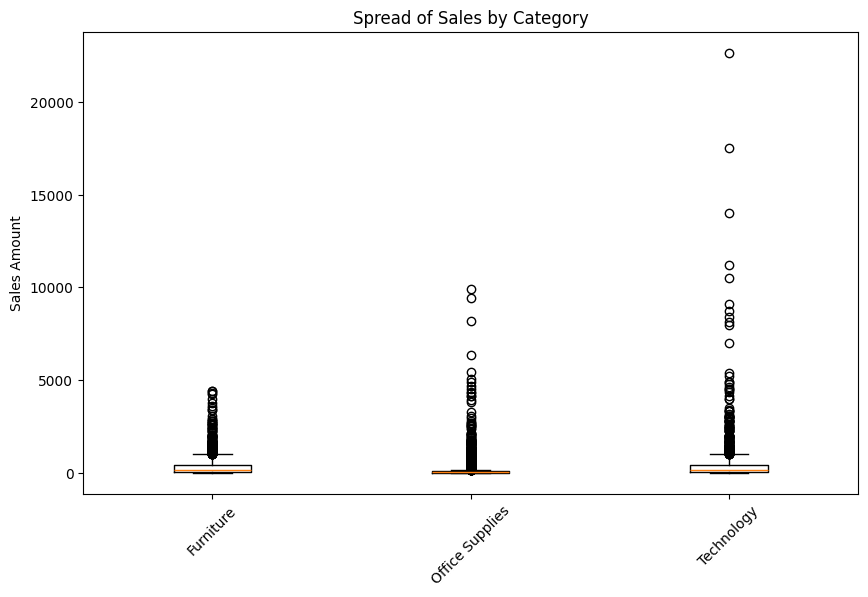

In [ ]:
# Plot 4: Box plot -> Spread of values (Sales split by Category)
fig, axes = plt.subplots(figsize=(10, 6))

if 'Category' in df_cleaned.columns:
    categories = df_cleaned['Category'].dropna().unique()
    # Create a list of arrays (one for each category's sales)
    sales_data = [df_cleaned[df_cleaned['Category'] == cat]['Sales'].dropna() for cat in categories]

    axes.boxplot(sales_data, tick_labels=categories)
    axes.set_title('Spread of Sales by Category')
    axes.set_ylabel('Sales Amount')
    axes.tick_params(axis='x', rotation=45)

**Key Insights:** There are extreme outliers in both revenue and profit. While the average order value is only **&#36;229.86**, the maximum single order reached a massive **&#36;22,638.48**.
Furthermore, there are significant anomalies in profitability;
the largest single loss on an order was **-&#36;6,599.98** (a Cubify CubeX 3D Printer), showing that deep discounts or high costs occasionally severely damage margins

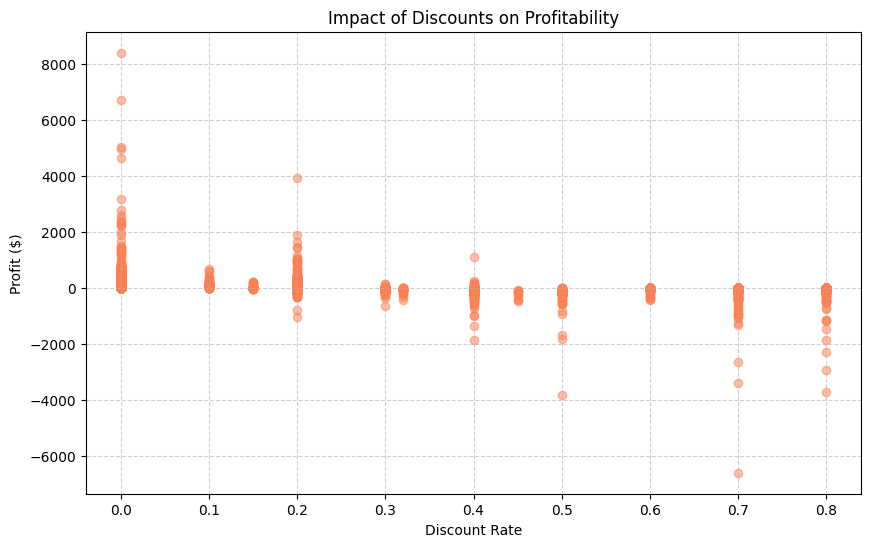

In [ ]:
import seaborn as sns
# Plot 5: Scatter Plot showing the relationaship between Discount and Profit
plt.figure(figsize=(10, 6))
plt.scatter(df_cleaned['Discount'], df_cleaned['Profit'], alpha=0.5, color='coral')
plt.title('Impact of Discounts on Profitability')
plt.xlabel('Discount Rate')
plt.ylabel('Profit ($)')
plt.grid(True, linestyle='--', alpha=0.6)

**Key Insight:** Impact of Discounts on Profitability:
This chart clearly illustrates the danger of over-discounting.
As the discount rate increases along the x-axis, the profit plunges significantly below zero, confirming that heavy discounts are the primary driver of major financial losses on individual transactions.

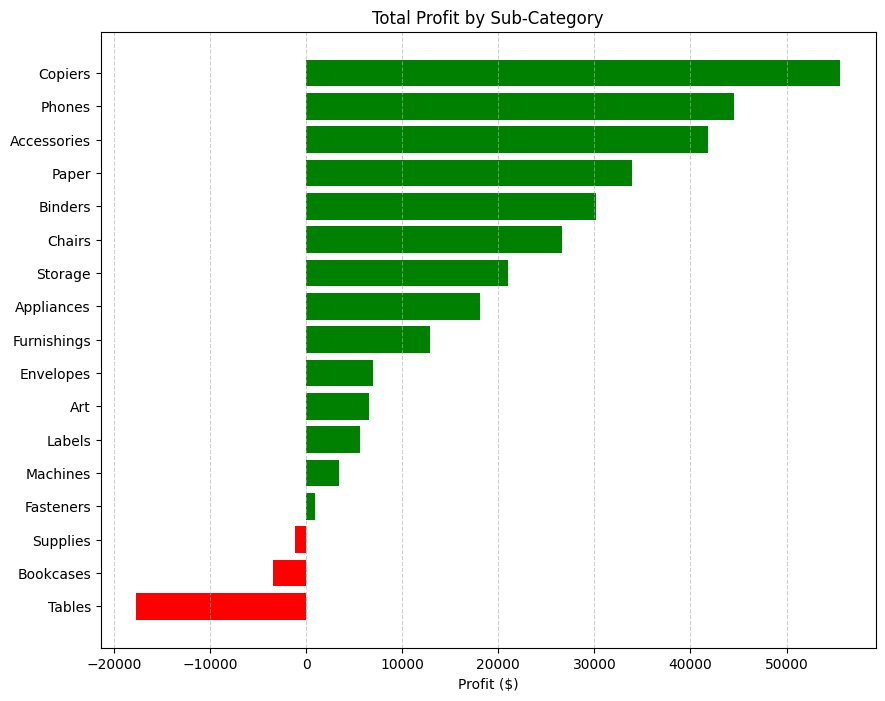

In [ ]:
# Plot 6: Horizontal Bar Chart - Total Profit by Product Sub-Category
subcat_profit = df_cleaned.groupby('Sub-Category')['Profit'].sum().sort_values()
colors = ['red' if x < 0 else 'green' for x in subcat_profit]
plt.figure(figsize=(10, 8))
plt.barh(subcat_profit.index, subcat_profit.values, color=colors)
plt.title('Total Profit by Sub-Category')
plt.xlabel('Profit ($)')
plt.grid(axis='x', linestyle='--', alpha=0.6)

**Key Insight:** Total Profit by Sub-Category;
Breaking down the high-level categories reveals hidden issues.
While Furniture as a whole might seem fine, this chart highlights that "Tables" and "Bookcases" are consistently losing money for the business (shown in red). Conversely, "Copiers" and "Phones" are massive profit drivers.

(array([0, 1, 2, 3]),
 [Text(0, 0, 'Central'),
  Text(1, 0, 'East'),
  Text(2, 0, 'South'),
  Text(3, 0, 'West')])

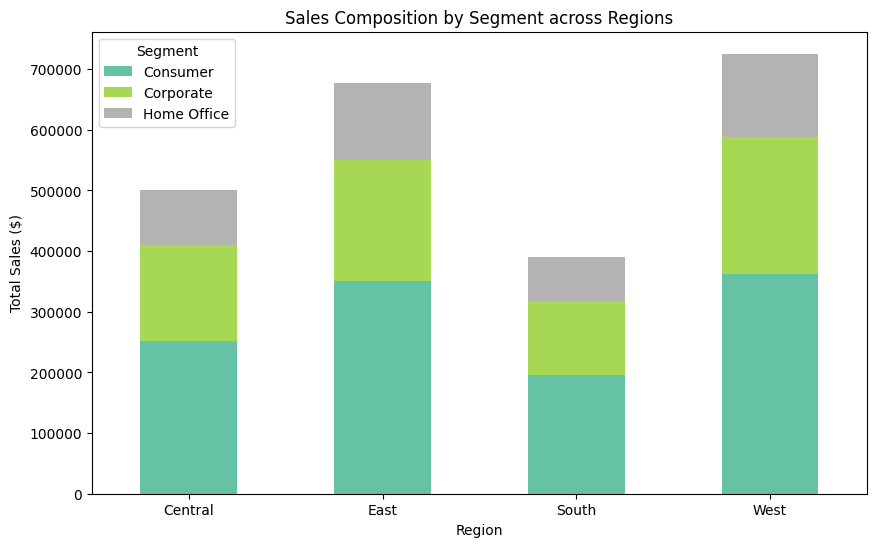

In [ ]:
# Plot 7: Stacked Bar Chart -  Sales Composition by Segment across Regions
segment_region = df_cleaned.groupby(['Region', 'Segment'])['Sales'].sum().unstack()

plt.figure(figsize=(10, 6))

segment_region.plot(kind='bar', stacked=True, colormap='Set2', ax=plt.gca())
plt.title('Sales Composition by Segment across Regions')
plt.xlabel('Region')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=0)

**Key Insight:** Sales Composition by Segment across Regions:
This visualization demonstrates that the "Consumer" segment makes up the largest proportion of sales across every single region. The "West" and "East" regions generate the most total revenue, but the ratio of Consumer, Corporate, and Home Office buyers remains relatively consistent nationwide.

Text(0.5, 1.0, 'Correlation Heatmap of Key Metrics')

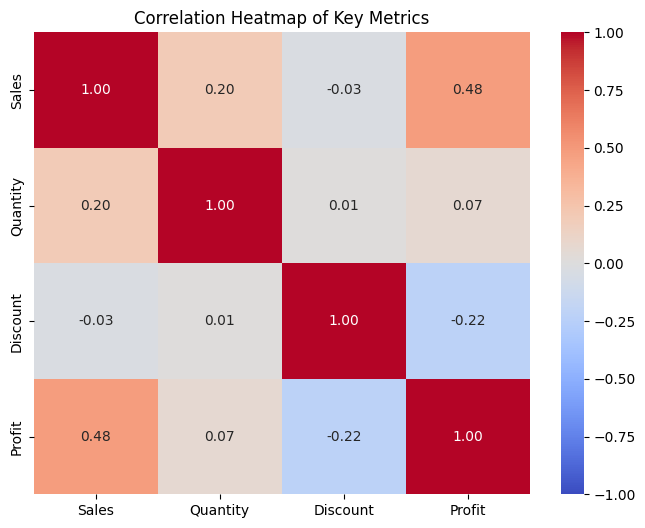

In [ ]:
# Plot 8: Heatmap showing correlation between Sales, Profit, Discount & Quantity
corr_matrix = df_cleaned[['Sales', 'Quantity', 'Discount', 'Profit']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Heatmap of Key Metrics')

**Key Insight:** Correlation Matrix of Key Metrics: The heatmap statistically confirms the patterns seen in the other charts. There is a notable positive correlation (0.48) between Sales and Profit, meaning higher sales generally yield higher profit.
However, there is a negative correlation (-0.22) between Discount and Profit, statistically validating that as discounts increase, profits decrease.

In [ ]:
df_cleaned.to_csv('superstore_cleaned.csv', index=False)